In [20]:
import datetime
import math

import geode
import geode.data.filter
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs

In [21]:
start_time = datetime.datetime(2026,9,13,3,0,tzinfo=datetime.UTC)
end_time = datetime.datetime(2026,9,13,8,59,tzinfo=datetime.UTC)
resulta = geode.get("atms_n20", start_time, end_time)
result = geode.get("atms_n20",
                   start_time,
                   end_time, 
                   filters=[
                       {"channels": [1]},
                       {"region": {"name": "atlantic_basin"}}
                       ]
                    )

Getting data from file path: /scratch3/NCEPDEV/da/Hyundeok.Choi/geode_tmp/lake/atms_n20.icechunk
Getting data from file path: /scratch3/NCEPDEV/da/Hyundeok.Choi/geode_tmp/lake/atms_n20.icechunk


  2026-10-27T18:02:26.003092Z  WARN icechunk_arrow_object_store: The LocalFileSystem storage is not safe for concurrent commits. If more than one thread/process will attempt to commit at the same time, prefer using object stores.
    at icechunk-arrow-object-store/src/lib.rs:330

  2026-10-27T18:02:26.076724Z  WARN icechunk_arrow_object_store: The LocalFileSystem storage is not safe for concurrent commits. If more than one thread/process will attempt to commit at the same time, prefer using object stores.
    at icechunk-arrow-object-store/src/lib.rs:330



(124677,) (124677,) (124677, 1)


(124677,) (124677,) (124677,)


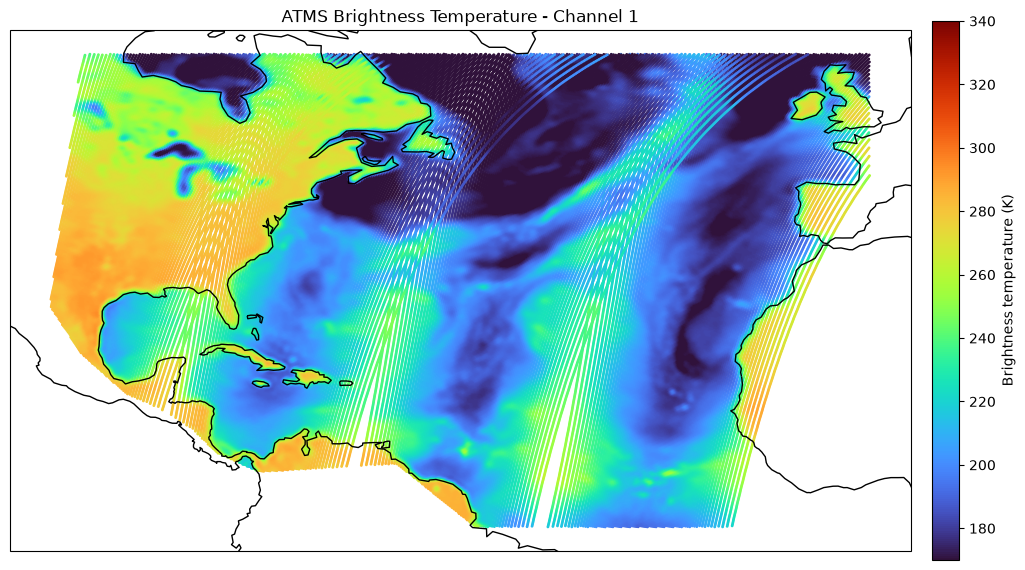

In [22]:
latitude_data = result["MetaData"].to_dataset()["latitude"]
longitude_data = result["MetaData"].to_dataset()["longitude"]
brightness_temperature_data = result["ObsValue"].to_dataset()["brightnessTemperature"]

print(latitude_data.shape, longitude_data.shape, brightness_temperature_data.shape)

latitude = latitude_data.values
longitude = longitude_data.values
brightness_temperature = brightness_temperature_data.values.flatten()

valid = (
    np.isfinite(latitude)
    & np.isfinite(longitude)
    & np.isfinite(brightness_temperature)
)
print(valid.shape, longitude.shape, brightness_temperature.shape)
figure, axis = plt.subplots(
    figsize=(14, 7), subplot_kw={"projection": ccrs.PlateCarree()}
)
points = axis.scatter(
    longitude[valid],
    latitude[valid],
    c=brightness_temperature[valid],
    s=1,
    vmin=170,
    vmax=340,
    cmap="turbo",
    transform=ccrs.PlateCarree(),
    rasterized=True,
)
axis.coastlines()
#axis.set_global()
axis.set_title("ATMS Brightness Temperature - Channel 1")
figure.colorbar(points, ax=axis, label="Brightness temperature (K)", pad=0.02)
plt.show()